In [1]:
using LinearAlgebra
using DifferentialEquations
using Plots
using LaTeXStrings

using Distributed

BLAS.set_num_threads(1)
addprocs(71, enable_threaded_blas=false);

In [2]:
gr();
# pyplot();
# plotlyjs();

In [3]:
@everywhere using Revise
@everywhere push!(LOAD_PATH, pwd())
using RMTProblems  # Load on a single node first in case recompilation is needed
using RMTSolver    # Load on a single node first in case recompilation is needed
@everywhere workers() using RMTProblems
@everywhere workers() using RMTSolver

# Dynamics of a partially symmetric CIM

$$
\frac{d x_i}{dt} = a x_i - x_i^3 + \sum_{j = 1}^N J_{ij} x_j \ .
$$

Let's run some simulations.

In [4]:
function network_f(dx, x, Jeff, t)
    mul!(dx, Jeff, x)
    dx .-= x .^ 3
end

function network_jac(jac, x, Jeff, t)
    jac .= Jeff
    for i in 1:length(x)
        jac[i, i] -= 3 * (x[i] * x[i])
    end
end

network = ODEFunction(network_f, jac=network_jac)
solver = Vern8();

In [5]:
N = 400
a = -0.5
τ = 0.5;

In [6]:
using RMTUtils

J = (1 / sqrt(N)) * randn(N, N)
J = RMTUtils.partially_hermitize(J, τ)
J[diagind(J)] .= 0.0;


Jeff = copy(J)
Jeff[diagind(Jeff)] .= a;

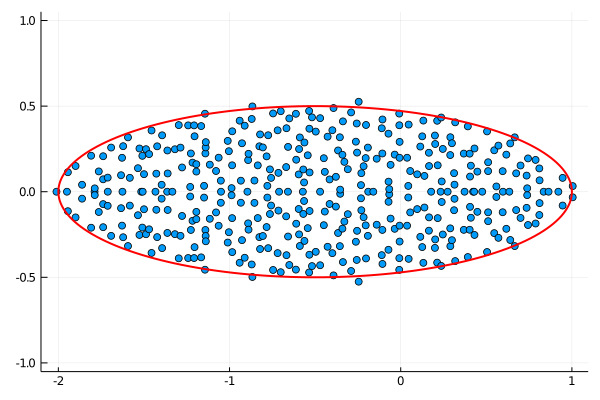

In [7]:
evs = eigvals(Jeff)
scatter(real(evs), imag(evs), aspect_ratio=:equal, label="")
plot!(
    t -> (1 / sqrt(2)) * (1 + τ) * (cos(t) - sin(t)) + a,
    t -> (1 / sqrt(2)) * (1 - τ) * (cos(t) + sin(t)),
    0,
    2pi,
    label="",
    color=:red,
    linewidth=2,
) 

In [8]:
x0 = randn(N);

In [9]:
# Verify Jacobian
function poor_mans_network_jac(jac, x, Jeff, t, dx)
    xx = copy(x)
    
    f = similar(xx)
    fdf = similar(xx)

    network_f(f, xx, Jeff, t)
    for j in 1:N
        xx[j] += dx
        network_f(fdf, xx, Jeff, t) 
        jac[:, j] = (fdf - f) / dx
        xx[j] = x[j]
    end
end

jaca = similar(Jeff)
jacb = similar(Jeff)
network_jac(jaca, x0, Jeff, 0.0)
poor_mans_network_jac(jacb, x0, Jeff, 0.0, 1e-6)

opnorm(jacb - jaca)

1.0132995537646129e-5

In [10]:
saveat = 5.0 / 3.0;

In [11]:
tspan_short = (0.0, 100.0)
problem_short = ODEProblem(network, x0, tspan_short, Jeff)
solution_short = solve(problem_short, solver, saveat=saveat);

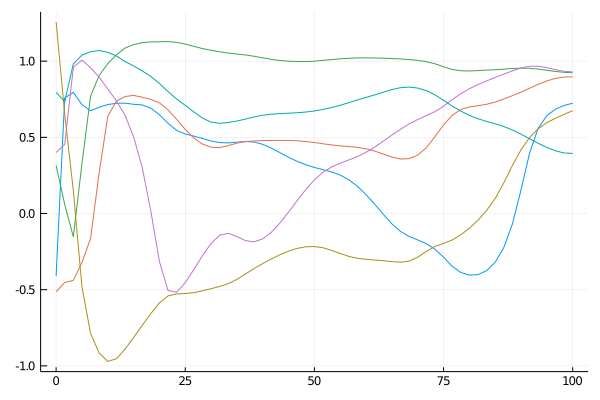

In [12]:
plot(solution_short.t, solution_short[1:6, :]', label="")

In [13]:
tspan = (0.0, 2000.0)
problem = ODEProblem(network, x0, tspan, Jeff)
solution = solve(problem, solver, saveat=saveat);

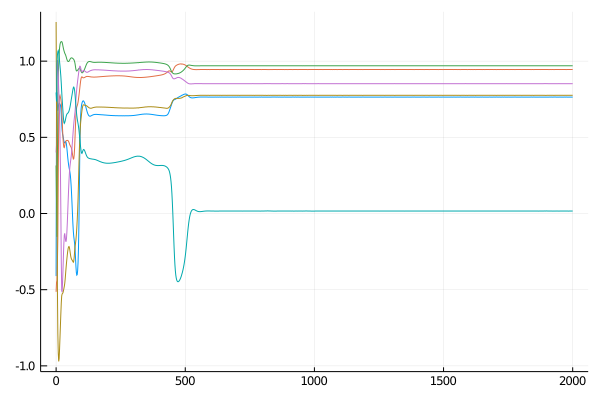

In [14]:
plot(solution.t, solution[1:6, :]', label="")

Fixed point found. Let's study it.

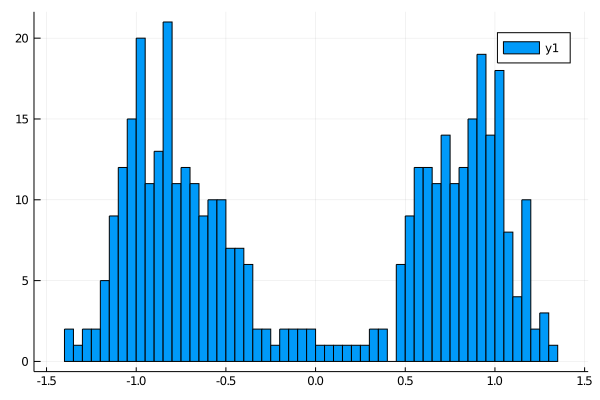

In [15]:
histogram(solution[end], bins=101)

In [16]:
M = Diagonal(complex(a .- (3 * (solution[end] .^ 2))))

rmtproblem = RMTProblem(M, complex(1.0) * I, complex(1.0) * I)

RMTProblem{Diagonal{Complex{Float64},Array{Complex{Float64},1}},UniformScaling{Complex{Float64}}}(Complex{Float64}[-2.2519542937918895 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im -3.1792808261629197 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; … ; 0.0 + 0.0im 0.0 + 0.0im … -3.1809911211012483 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im -4.682100015094753 + 0.0im], UniformScaling{Complex{Float64}}(1.0 + 0.0im), UniformScaling{Complex{Float64}}(1.0 + 0.0im), UniformScaling{Complex{Float64}}(1.0 - 0.0im), Complex{Float64}[-2.2519542937918895 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im -3.1792808261629197 + 0.0im … 0.0 + 0.0im 0.0 + 0.0im; … ; 0.0 + 0.0im 0.0 + 0.0im … -3.1809911211012483 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im … 0.0 + 0.0im -4.682100015094753 + 0.0im])

In [17]:
Mevs = unique(eigvals(rmtproblem.M))

LJR = rmtproblem.L * J * rmtproblem.R
A = rmtproblem.M + LJR

Aevs = eigvals(A)
Jevs = eigvals(J);

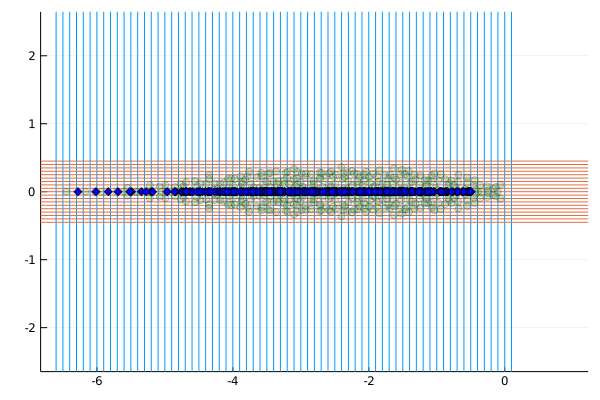

In [27]:
xs = -6.6:0.1:0.1
ys = -0.45:0.05:0.45

vline(xs, label="")
hline!(ys, label="")
scatter!(real(Aevs), imag(Aevs), alpha=0.25, aspect_ratio=:equal, label="")
scatter!(real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

In [28]:
dτ = 0.025

b = 4.0 / 3.0
n = 17

@everywhere gsq_solver, K_solver = rmt_solvers(
    problem=$rmtproblem, τ=$τ, dτ=$dτ, b=$b, n=$n
)

In [31]:
z = -4.0 + 0.35im

q, gsq, gsq_seq, q_seq, K_seq = gsq_solver(z, verbose=true);

  z = -4.000 + i 0.350
--------------------------------------------
   g^2               q                K
--------------------------------------------
 1.33e+02  -4.97e-03 + i-1.29e-03   7.34e-03
 9.97e+01  -6.53e-03 + i-1.71e-03   9.71e-03
 7.47e+01  -8.55e-03 + i-2.26e-03   1.28e-02
 5.60e+01  -1.11e-02 + i-2.98e-03   1.69e-02
 4.20e+01  -1.44e-02 + i-3.92e-03   2.22e-02
 3.14e+01  -1.85e-02 + i-5.14e-03   2.90e-02
 2.35e+01  -2.35e-02 + i-6.72e-03   3.77e-02
 1.76e+01  -2.96e-02 + i-8.74e-03   4.87e-02
 1.32e+01  -3.68e-02 + i-1.13e-02   6.26e-02
 9.86e+00  -4.51e-02 + i-1.46e-02   7.99e-02
 7.36e+00  -5.45e-02 + i-1.87e-02   1.01e-01
 5.48e+00  -6.50e-02 + i-2.38e-02   1.28e-01
 4.07e+00  -7.63e-02 + i-3.03e-02   1.60e-01
 3.01e+00  -8.83e-02 + i-3.85e-02   1.98e-01
 2.21e+00  -1.01e-01 + i-4.88e-02   2.45e-01
 1.61e+00  -1.14e-01 + i-6.18e-02   3.00e-01
 1.15e+00  -1.27e-01 + i-7.86e-02   3.67e-01
 7.97e-01  -1.40e-01 + i-1.00e-01   4.46e-01
 5.20e-01  -1.53e-01 + i-1.29e-01   5

In [32]:
zs = [complex(x, y) for y in ys, x in xs]
q_gsqs = pmap(gsq_solver, zs);

      From worker 37:	  z = -6.600 + i-0.450
      From worker 9:	  z = -6.600 + i-0.400
      From worker 6:	  z = -6.600 + i-0.350
      From worker 70:	  z = -6.600 + i-0.250
      From worker 67:	  z = -6.600 + i 0.100
      From worker 22:	  z = -6.600 + i 0.200
      From worker 61:	  z = -6.600 + i 0.300
      From worker 57:	  z = -6.600 + i 0.400
      From worker 24:	  z = -6.500 + i-0.450
      From worker 47:	  z = -6.600 + i-0.150
      From worker 51:	  z = -6.500 + i-0.200
      From worker 46:	  z = -6.500 + i-0.100
      From worker 55:	  z = -6.500 + i 0.000
      From worker 42:	  z = -6.500 + i 0.100
      From worker 25:	  z = -6.500 + i 0.200
      From worker 39:	  z = -6.500 + i 0.300
      From worker 23:	  z = -6.500 + i 0.400
      From worker 48:	  z = -6.400 + i-0.450
      From worker 18:	  z = -6.400 + i-0.350
      From worker 35:	  z = -6.400 + i-0.250
      From worker 50:	  z = -6.400 + i-0.150
      From worker 52:	  z = -6.400 + i-0.050
      From w

      From worker 71:	  q =       NaN + i      NaN
      From worker 71:	g^2 =       NaN
      From worker 71:	  z = -6.100 + i 0.300
      From worker 44:	  q =       NaN + i      NaN
      From worker 44:	g^2 =       NaN
      From worker 44:	  z = -6.100 + i 0.350
      From worker 49:	  q =       NaN + i      NaN
      From worker 49:	g^2 =       NaN
      From worker 59:	  q =       NaN + i      NaN
      From worker 59:	g^2 =       NaN
      From worker 49:	  z = -6.100 + i 0.400
      From worker 59:	  z = -6.100 + i 0.450
      From worker 13:	  q =       NaN + i      NaN
      From worker 13:	g^2 =       NaN
      From worker 13:	  z = -6.000 + i-0.450
      From worker 25:	  q =       NaN + i      NaN
      From worker 25:	g^2 =       NaN
      From worker 67:	  q =       NaN + i      NaN
      From worker 67:	g^2 =       NaN
      From worker 25:	  z = -6.000 + i-0.400
      From worker 64:	  q =       NaN + i      NaN
      From worker 64:	g^2 =       NaN
      From worker 

      From worker 25:	  z = -5.700 + i-0.450
      From worker 67:	  q =       NaN + i      NaN
      From worker 67:	g^2 =       NaN
      From worker 67:	  z = -5.700 + i-0.400
      From worker 66:	  q =       NaN + i      NaN
      From worker 66:	g^2 =       NaN
      From worker 5:	  q =       NaN + i      NaN
      From worker 5:	g^2 =       NaN
      From worker 5:	  z = -5.700 + i-0.300
      From worker 66:	  z = -5.700 + i-0.350
      From worker 23:	  q =       NaN + i      NaN
      From worker 23:	g^2 =       NaN
      From worker 19:	  q =       NaN + i      NaN
      From worker 19:	g^2 =       NaN
      From worker 23:	  z = -5.700 + i-0.250
      From worker 19:	  z = -5.700 + i-0.200
      From worker 28:	  q =       NaN + i      NaN
      From worker 28:	g^2 =       NaN
      From worker 28:	  z = -5.700 + i-0.150
      From worker 39:	  q =       NaN + i      NaN
      From worker 39:	g^2 =       NaN
      From worker 39:	  z = -5.700 + i-0.100
      From worker 16

      From worker 19:	  q = -2.04e-01 + i 2.00e-01
      From worker 19:	g^2 = -1.51e-01
      From worker 19:	  z = -5.400 + i-0.200
      From worker 60:	  q = -2.04e-01 + i-2.00e-01
      From worker 60:	g^2 = -1.51e-01
      From worker 60:	  z = -5.400 + i-0.150
      From worker 20:	  q = -2.06e-01 + i 3.50e-01
      From worker 20:	g^2 = -4.87e-01
      From worker 20:	  z = -5.400 + i-0.100
      From worker 34:	  q = -2.04e-01 + i-2.50e-01
      From worker 34:	g^2 = -2.41e-01
      From worker 34:	  z = -5.400 + i-0.050
      From worker 21:	  q = -2.13e-01 + i 3.00e-01
      From worker 21:	g^2 = -3.51e-01
      From worker 21:	  z = -5.400 + i 0.000
      From worker 6:	  q = -2.13e-01 + i 1.50e-01
      From worker 6:	g^2 = -8.13e-02
      From worker 10:	  q = -2.06e-01 + i-2.50e-01
      From worker 10:	g^2 = -2.47e-01
      From worker 6:	  z = -5.400 + i 0.050
      From worker 10:	  z = -5.400 + i 0.100
      From worker 4:	  q = -2.13e-01 + i 2.00e-01
      From work

      From worker 21:	  q = -2.20e-01 + i 0.00e+00
      From worker 21:	g^2 =  1.43e-02
      From worker 21:	  z = -5.100 + i 0.050
      From worker 15:	  q = -2.18e-01 + i-2.50e-01
      From worker 15:	g^2 = -2.37e-01
      From worker 15:	  z = -5.100 + i 0.100
      From worker 30:	  q = -2.18e-01 + i-3.50e-01
      From worker 30:	g^2 = -4.77e-01
      From worker 30:	  z = -5.100 + i 0.150
      From worker 25:	  q = -2.18e-01 + i-4.00e-01
      From worker 25:	g^2 = -6.27e-01
      From worker 25:	  z = -5.100 + i 0.200
      From worker 63:	  q = -2.43e-01 + i 0.00e+00
      From worker 63:	g^2 =  1.01e-02
      From worker 63:	  z = -5.100 + i 0.250
      From worker 26:	  q = -2.18e-01 + i-3.00e-01
      From worker 26:	g^2 = -3.47e-01
      From worker 26:	  z = -5.100 + i 0.300
      From worker 12:	  q = -2.20e-01 + i 4.50e-01
      From worker 12:	g^2 = -7.96e-01
      From worker 12:	  z = -5.100 + i 0.350
      From worker 8:	  q = -2.60e-01 + i 0.00e+00
      From w

...

      From worker 72:	  q =  1.21e-01 + i 1.50e-01
      From worker 72:	g^2 =  3.18e-01
      From worker 72:	  z = -1.200 + i 0.250
      From worker 11:	  q =  1.21e-01 + i-2.00e-01
      From worker 11:	g^2 =  2.48e-01
      From worker 11:	  z = -1.200 + i 0.300
      From worker 63:	  q =  1.21e-01 + i-1.50e-01
      From worker 63:	g^2 =  3.18e-01
      From worker 63:	  z = -1.200 + i 0.350
      From worker 24:	  q =  1.36e-01 + i 4.00e-01
      From worker 24:	g^2 = -2.44e-01
      From worker 24:	  z = -1.200 + i 0.400
      From worker 69:	  q =  1.66e-01 + i 0.00e+00
      From worker 69:	g^2 =  3.66e-01
      From worker 69:	  z = -1.200 + i 0.450
      From worker 53:	  q =  1.36e-01 + i 3.50e-01
      From worker 53:	g^2 = -9.39e-02
      From worker 53:	  z = -1.100 + i-0.450
      From worker 18:	  q =  1.36e-01 + i 3.00e-01
      From worker 18:	g^2 =  3.61e-02
      From worker 18:	  z = -1.100 + i-0.400
      From worker 61:	  q =  1.36e-01 + i 5.00e-02
      From 

      From worker 4:	  q =  1.81e-01 + i 1.00e-01
      From worker 4:	g^2 =  3.06e-01
      From worker 4:	  z = -0.800 + i-0.400
      From worker 8:	  q =  1.81e-01 + i 3.00e-01
      From worker 8:	g^2 = -1.38e-02
      From worker 8:	  z = -0.800 + i-0.350
      From worker 70:	  q =  2.11e-01 + i 0.00e+00
      From worker 70:	g^2 =  2.99e-01
      From worker 70:	  z = -0.800 + i-0.300
      From worker 64:	  q =  1.81e-01 + i-1.00e-01
      From worker 64:	g^2 =  3.06e-01
      From worker 64:	  z = -0.800 + i-0.250
      From worker 9:	  q =  1.81e-01 + i 2.00e-01
      From worker 9:	g^2 =  1.86e-01
      From worker 9:	  z = -0.800 + i-0.200
      From worker 6:	  q =  1.81e-01 + i 1.50e-01
      From worker 6:	g^2 =  2.56e-01
      From worker 6:	  z = -0.800 + i-0.150
      From worker 13:	  q =  1.81e-01 + i 3.50e-01
      From worker 13:	g^2 = -1.44e-01
      From worker 13:	  z = -0.800 + i-0.100
      From worker 42:	  q =  1.81e-01 + i-1.50e-01
      From worker 42:	g

      From worker 62:	  q =  2.26e-01 + i-1.00e-01
      From worker 62:	g^2 =  2.32e-01
      From worker 62:	  z = -0.500 + i-0.150
      From worker 43:	  q =  2.26e-01 + i 3.00e-01
      From worker 43:	g^2 = -8.83e-02
      From worker 43:	  z = -0.500 + i-0.100
      From worker 57:	  q =  2.26e-01 + i-2.00e-01
      From worker 57:	g^2 =  1.12e-01
      From worker 57:	  z = -0.500 + i-0.050
      From worker 14:	  q =  2.26e-01 + i-1.50e-01
      From worker 14:	g^2 =  1.82e-01
      From worker 14:	  z = -0.500 + i 0.000
      From worker 30:	  q =  2.26e-01 + i-2.50e-01
      From worker 30:	g^2 =  2.17e-02
      From worker 30:	  z = -0.500 + i 0.050
      From worker 36:	  q =  2.26e-01 + i-3.50e-01
      From worker 36:	g^2 = -2.18e-01
      From worker 46:	  q =  2.52e-01 + i 0.00e+00
      From worker 46:	g^2 =  2.12e-01
      From worker 36:	  z = -0.500 + i 0.100
      From worker 46:	  z = -0.500 + i 0.150
      From worker 34:	  q =  2.26e-01 + i-4.00e-01
      From 

      From worker 14:	  q =  2.72e-01 + i 0.00e+00
      From worker 14:	g^2 =  1.52e-01
      From worker 14:	  z = -0.200 + i 0.100
      From worker 2:	  q =  2.72e-01 + i 4.50e-01
      From worker 2:	g^2 = -6.58e-01
      From worker 2:	  z = -0.200 + i 0.150
      From worker 39:	  q =  2.72e-01 + i 4.00e-01
      From worker 39:	g^2 = -4.88e-01
      From worker 39:	  z = -0.200 + i 0.200
      From worker 17:	  q =  2.72e-01 + i 2.50e-01
      From worker 17:	g^2 = -9.79e-02
      From worker 17:	  z = -0.200 + i 0.250
      From worker 32:	  q =  2.72e-01 + i 3.00e-01
      From worker 32:	g^2 = -2.08e-01
      From worker 32:	  z = -0.200 + i 0.300
      From worker 12:	  q =  2.63e-01 + i-4.50e-01
      From worker 12:	g^2 = -6.29e-01
      From worker 12:	  z = -0.200 + i 0.350
      From worker 43:	  q =  2.72e-01 + i 1.00e-01
      From worker 43:	g^2 =  1.12e-01
      From worker 43:	  z = -0.200 + i 0.400
      From worker 57:	  q =  2.72e-01 + i 5.00e-02
      From wor

      From worker 19:	  q =  2.98e-01 + i 2.50e-01
      From worker 19:	g^2 = -1.72e-01
      From worker 45:	  q =  2.98e-01 + i 1.50e-01
      From worker 45:	g^2 = -1.16e-02
      From worker 19:	  z =  0.100 + i 0.350
      From worker 45:	  z =  0.100 + i 0.400
      From worker 3:	  q =  2.98e-01 + i 4.50e-01
      From worker 3:	g^2 = -7.32e-01
      From worker 3:	  z =  0.100 + i 0.450
      From worker 27:	  q =  2.98e-01 + i 1.00e-01
      From worker 27:	g^2 =  3.84e-02
      From worker 7:	  q =  2.98e-01 + i-5.00e-02
      From worker 7:	g^2 =  6.84e-02
      From worker 33:	  q =  2.98e-01 + i 4.00e-01
      From worker 33:	g^2 = -5.62e-01
      From worker 31:	  q =  2.98e-01 + i 3.50e-01
      From worker 31:	g^2 = -4.12e-01
      From worker 47:	  q =  2.98e-01 + i 3.00e-01
      From worker 47:	g^2 = -2.82e-01
      From worker 14:	  q =  2.98e-01 + i-1.00e-01
      From worker 14:	g^2 =  3.84e-02
      From worker 40:	  q =  2.98e-01 + i 2.00e-01
      From worker 

In [33]:
gsqs = similar(zs, Float64)
qs = similar(zs)
for i in 1:length(xs)
    for j in 1:length(ys)
        qs[j, i], gsqs[j, i] = q_gsqs[j, i]
    end
end

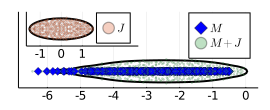

In [48]:
p = contour(
    xs,
    ys,
    gsqs,
    levels=[0.0],
    linewidth=2,
    color=:black,
    colorbar_entry=false,
    aspect_ratio=:equal,
    size=(270, 110),
    ylims=(-0.5, 1.8),
    yticks=[],
    # xlabel=L"\mathrm{Re}",
    # ylabel=L"\mathrm{Im}",
)
scatter!(
    p,
    real(Mevs),
    imag(Mevs),
    markershape=:diamond,
    markercolor=:blue,
    aspect_ratio=:equal,
    label=L"M",
)

plot!(
    p,
    t -> (1 + τ) * cos(t),
    t -> (1 - τ) * sin(t),
    0,
    2pi,
    linewidth=2,
    color=:black,
    aspect_ratio=:equal,
    label="",
    xlims=(-1.65, 3.65),
    xticks=[-1; 0; 1],
    yticks=[],
    inset_subplots=(1, bbox(0.033, 0.0, 0.467, 0.45)),
    subplot=2,
)

savefig(p, "boundary-real-cim.pdf")

scatter!(
    p,
    real(Aevs),
    imag(Aevs),
    markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    label=L"M + J",
    subplot=1,
)

scatter!(
    p,
    real(Jevs),
    imag(Jevs),
    markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    label=L"J",
    subplot=2,
)

savefig(p, "spectrum-real-cim.pdf")
p